In [1]:
!pip install transformers torch pillow -q


In [2]:
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
from PIL import Image
import torch

# Load the processor (handles image preprocessing) and the model itself
processor = TrOCRProcessor.from_pretrained("microsoft/trocr-large-handwritten")
model = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-large-handwritten")

# Move model to GPU if available, otherwise it'll run on CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

print(f"Model loaded successfully on {device}")

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


pytorch_model.bin:   0%|          | 0.00/2.23G [00:00<?, ?B/s]

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-large-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Model loaded successfully on cuda


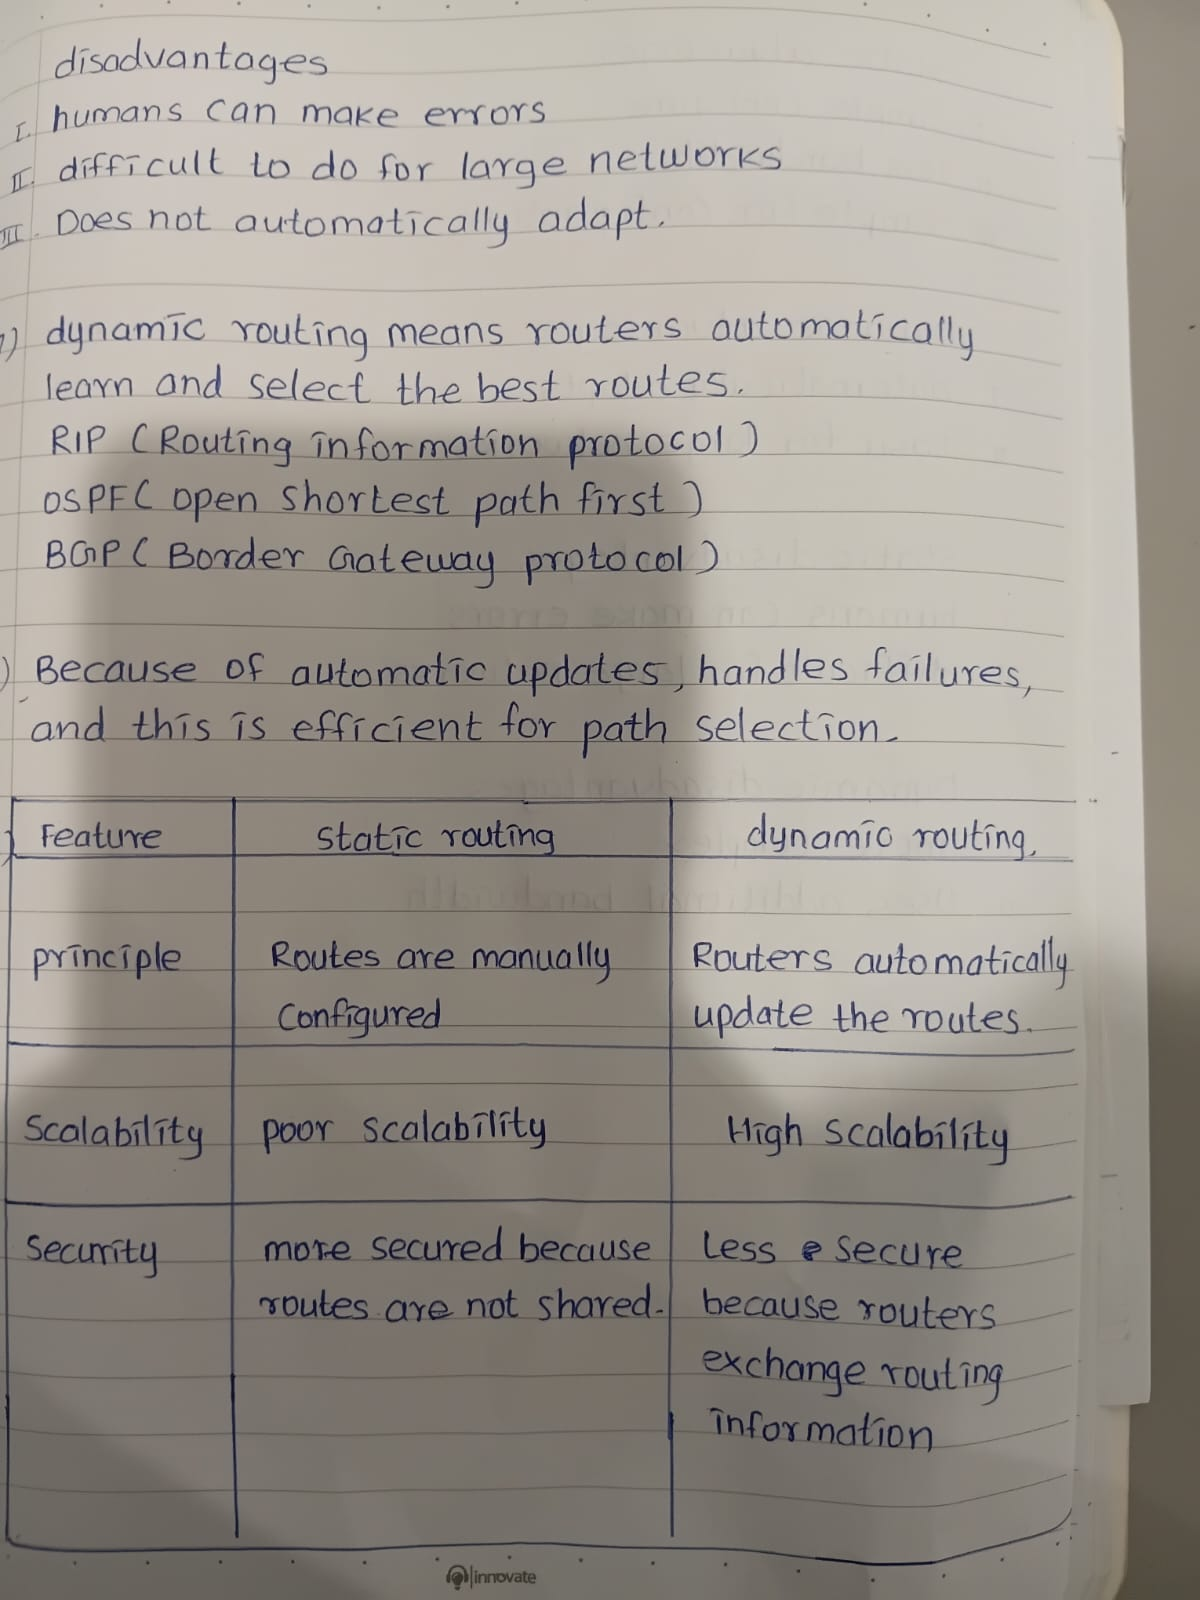

In [3]:
# Load your image
image = Image.open("/content/WhatsApp Image 2026-08-10 at 12.14.22.jpeg").convert("RGB")

# Show it so we can visually confirm it loaded right
image

In [4]:
# Step 1: Convert image into the numeric format the model expects
pixel_values = processor(images=image, return_tensors="pt").pixel_values.to(device)

# Step 2: Generate text from the image
generated_ids = model.generate(pixel_values)

# Step 3: Convert the model's output tokens back into readable text
generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

print("Extracted text:")
print(generated_text)

/usr/local/lib/python3.12/dist-packages/transformers/generation/utils.py:1258: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


Extracted text:
0 0


In [5]:
!pip install opencv-python-headless -q

In [6]:
import cv2
import numpy as np

# Load image in grayscale (easier to analyze ink vs paper)
img = cv2.imread("/content/WhatsApp Image 2026-08-10 at 12.14.22.jpeg", cv2.IMREAD_GRAYSCALE)

# Threshold: turn it into pure black/white so ink=white(255), paper=black(0)
# THRESH_BINARY_INV flips it so text becomes white on black background
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Sum up "ink" pixels per row -> gives us the horizontal projection profile
row_sums = np.sum(binary, axis=1)

# Print it out as numbers first so we can see the pattern before visualizing
print(row_sums[:50])  # just first 50 rows to peek

[24225 24735 25500 25755 24990 24990 24480 24480 23460 22695 22695 22440
 22440 22185 22185 22440 22695 22185 21675 21420 21420 21420 21165 21165
 21165 20910 20910 20910 20655 21165 21420 20910 20400 20400 20400 20145
 20145 19890 20400 20655 20655 20400 21420 21675 21675 21420 21930 22185
 21930 23970]


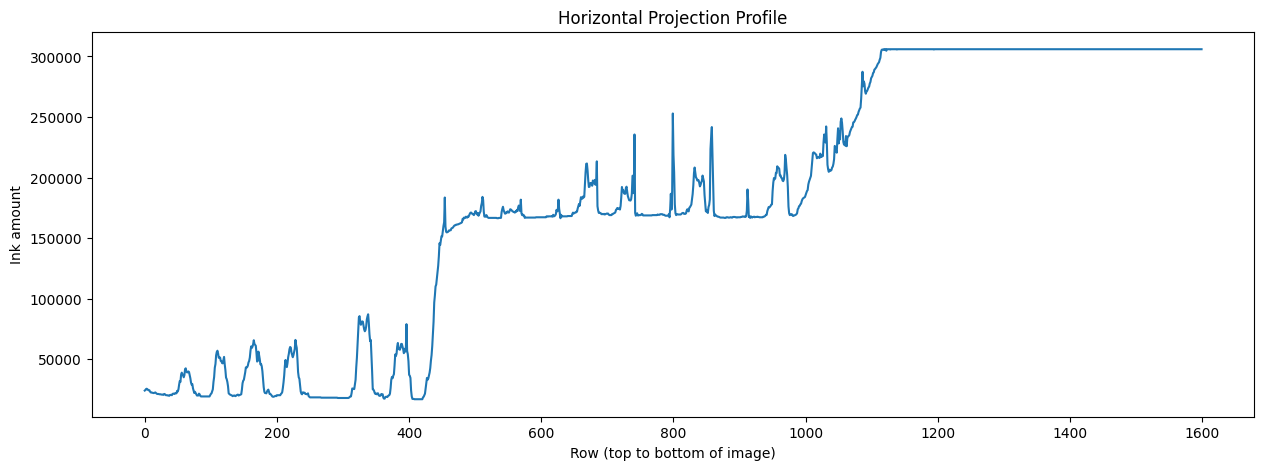

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.plot(row_sums)
plt.xlabel("Row (top to bottom of image)")
plt.ylabel("Ink amount")
plt.title("Horizontal Projection Profile")
plt.show()

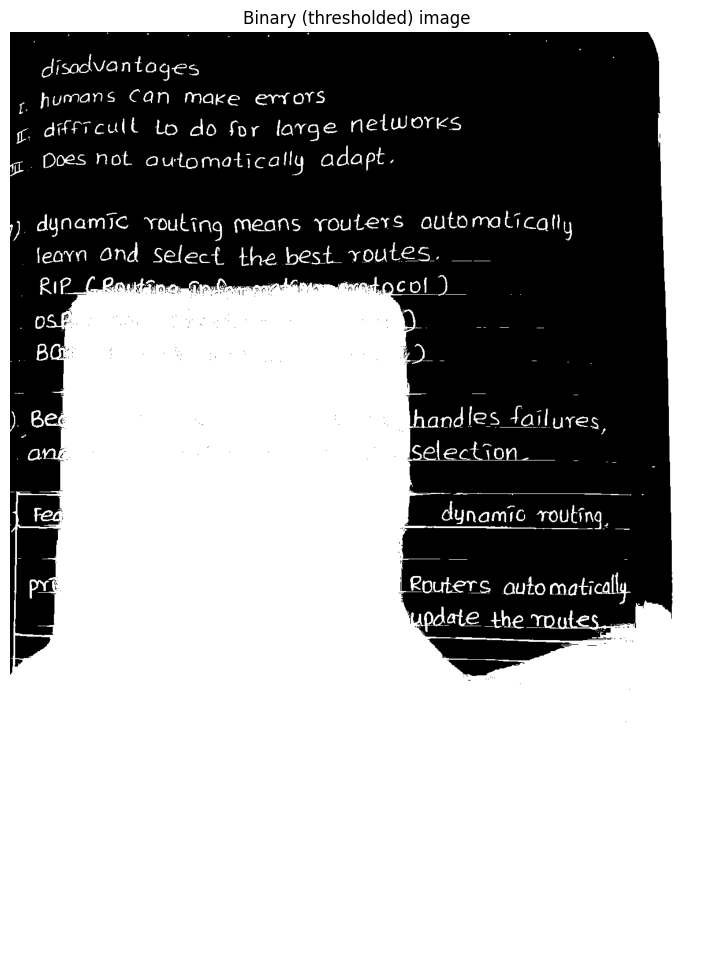

In [8]:
plt.figure(figsize=(10, 12))
plt.imshow(binary, cmap='gray')
plt.title("Binary (thresholded) image")
plt.axis('off')
plt.show()

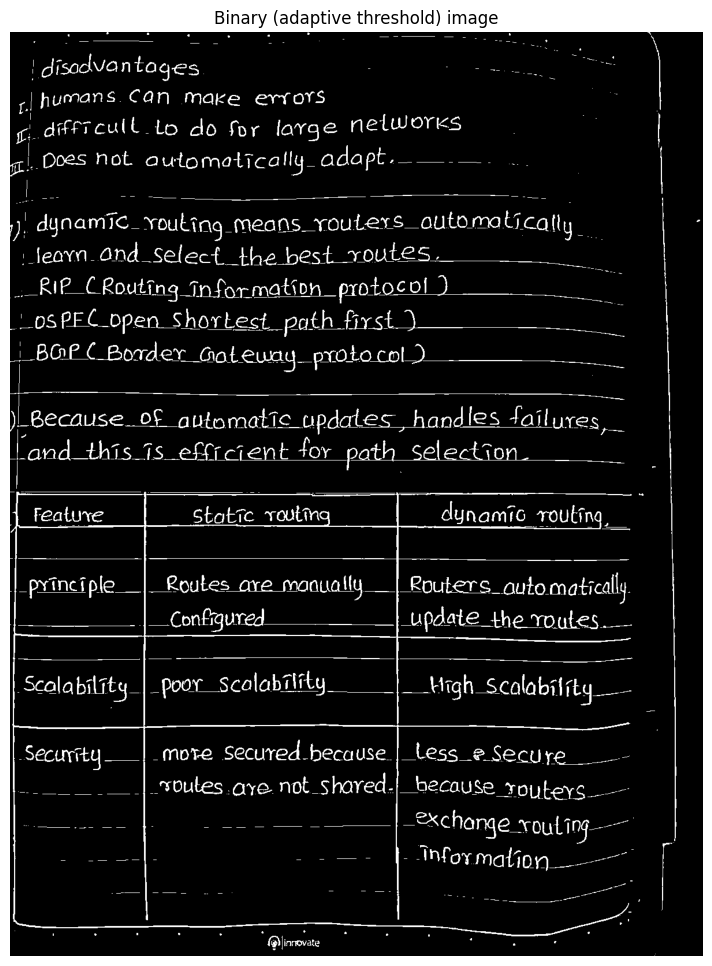

In [9]:
# Adaptive threshold instead of global Otsu
binary = cv2.adaptiveThreshold(
    img, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    blockSize=25,   # size of the local neighborhood considered
    C=15            # constant subtracted to fine-tune sensitivity
)

# Re-plot to see if it looks cleaner now
plt.figure(figsize=(10, 12))
plt.imshow(binary, cmap='gray')
plt.title("Binary (adaptive threshold) image")
plt.axis('off')
plt.show()

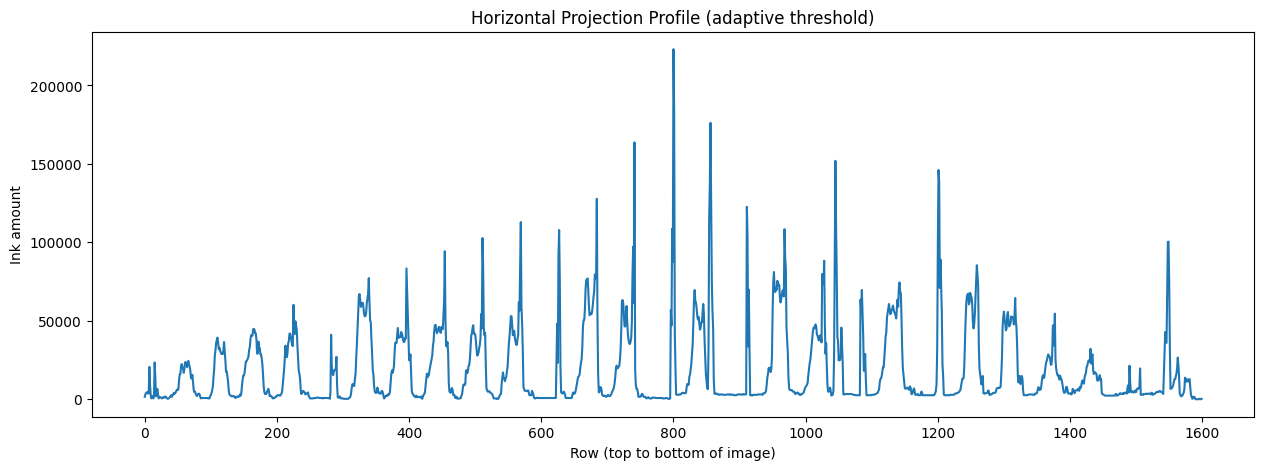

In [10]:
# Recompute row sums on the cleaned-up binary image
row_sums = np.sum(binary, axis=1)

plt.figure(figsize=(15, 5))
plt.plot(row_sums)
plt.xlabel("Row (top to bottom of image)")
plt.ylabel("Ink amount")
plt.title("Horizontal Projection Profile (adaptive threshold)")
plt.show()

In [11]:
# A small threshold to ignore tiny noise (dust, faint marks)
noise_threshold = 2000

# Find rows where there's meaningful ink
has_text = row_sums > noise_threshold

# Detect where text "starts" (False->True) and "ends" (True->False)
line_boundaries = []
in_line = False
start = 0

for i, val in enumerate(has_text):
    if val and not in_line:
        start = i
        in_line = True
    elif not val and in_line:
        line_boundaries.append((start, i))
        in_line = False

# Catch case where text runs to the very last row
if in_line:
    line_boundaries.append((start, len(has_text)))

print(f"Detected {len(line_boundaries)} lines")
print(line_boundaries)

Detected 23 lines
[(1, 10), (12, 13), (14, 17), (18, 21), (39, 41), (42, 84), (99, 132), (133, 135), (144, 191), (200, 249), (281, 292), (312, 362), (365, 408), (411, 412), (421, 470), (479, 527), (537, 589), (623, 637), (647, 697), (700, 747), (752, 755), (796, 1568), (1569, 1584)]


In [12]:
noise_threshold = 5000       # raised, to ignore small noise blips
min_line_height = 10         # a real line should span at least this many rows
min_gap = 8                  # gaps smaller than this get merged into the same line

has_text = row_sums > noise_threshold

# Step 1: find raw start/end boundaries
raw_boundaries = []
in_line = False
start = 0
for i, val in enumerate(has_text):
    if val and not in_line:
        start = i
        in_line = True
    elif not val and in_line:
        raw_boundaries.append((start, i))
        in_line = False
if in_line:
    raw_boundaries.append((start, len(has_text)))

# Step 2: merge boundaries that are separated by a very small gap
merged = []
for b in raw_boundaries:
    if merged and (b[0] - merged[-1][1]) < min_gap:
        merged[-1] = (merged[-1][0], b[1])  # extend previous line
    else:
        merged.append(list(b))

# Step 3: filter out fragments too short to be real lines
line_boundaries = [tuple(b) for b in merged if (b[1] - b[0]) >= min_line_height]

print(f"Detected {len(line_boundaries)} lines")
print(line_boundaries)

Detected 23 lines
[(7, 20), (48, 75), (102, 128), (147, 189), (208, 241), (282, 292), (313, 360), (372, 405), (425, 467), (481, 522), (540, 587), (652, 692), (708, 746), (820, 862), (940, 981), (998, 1057), (1110, 1165), (1197, 1209), (1233, 1278), (1288, 1330), (1351, 1448), (1487, 1507), (1535, 1583)]


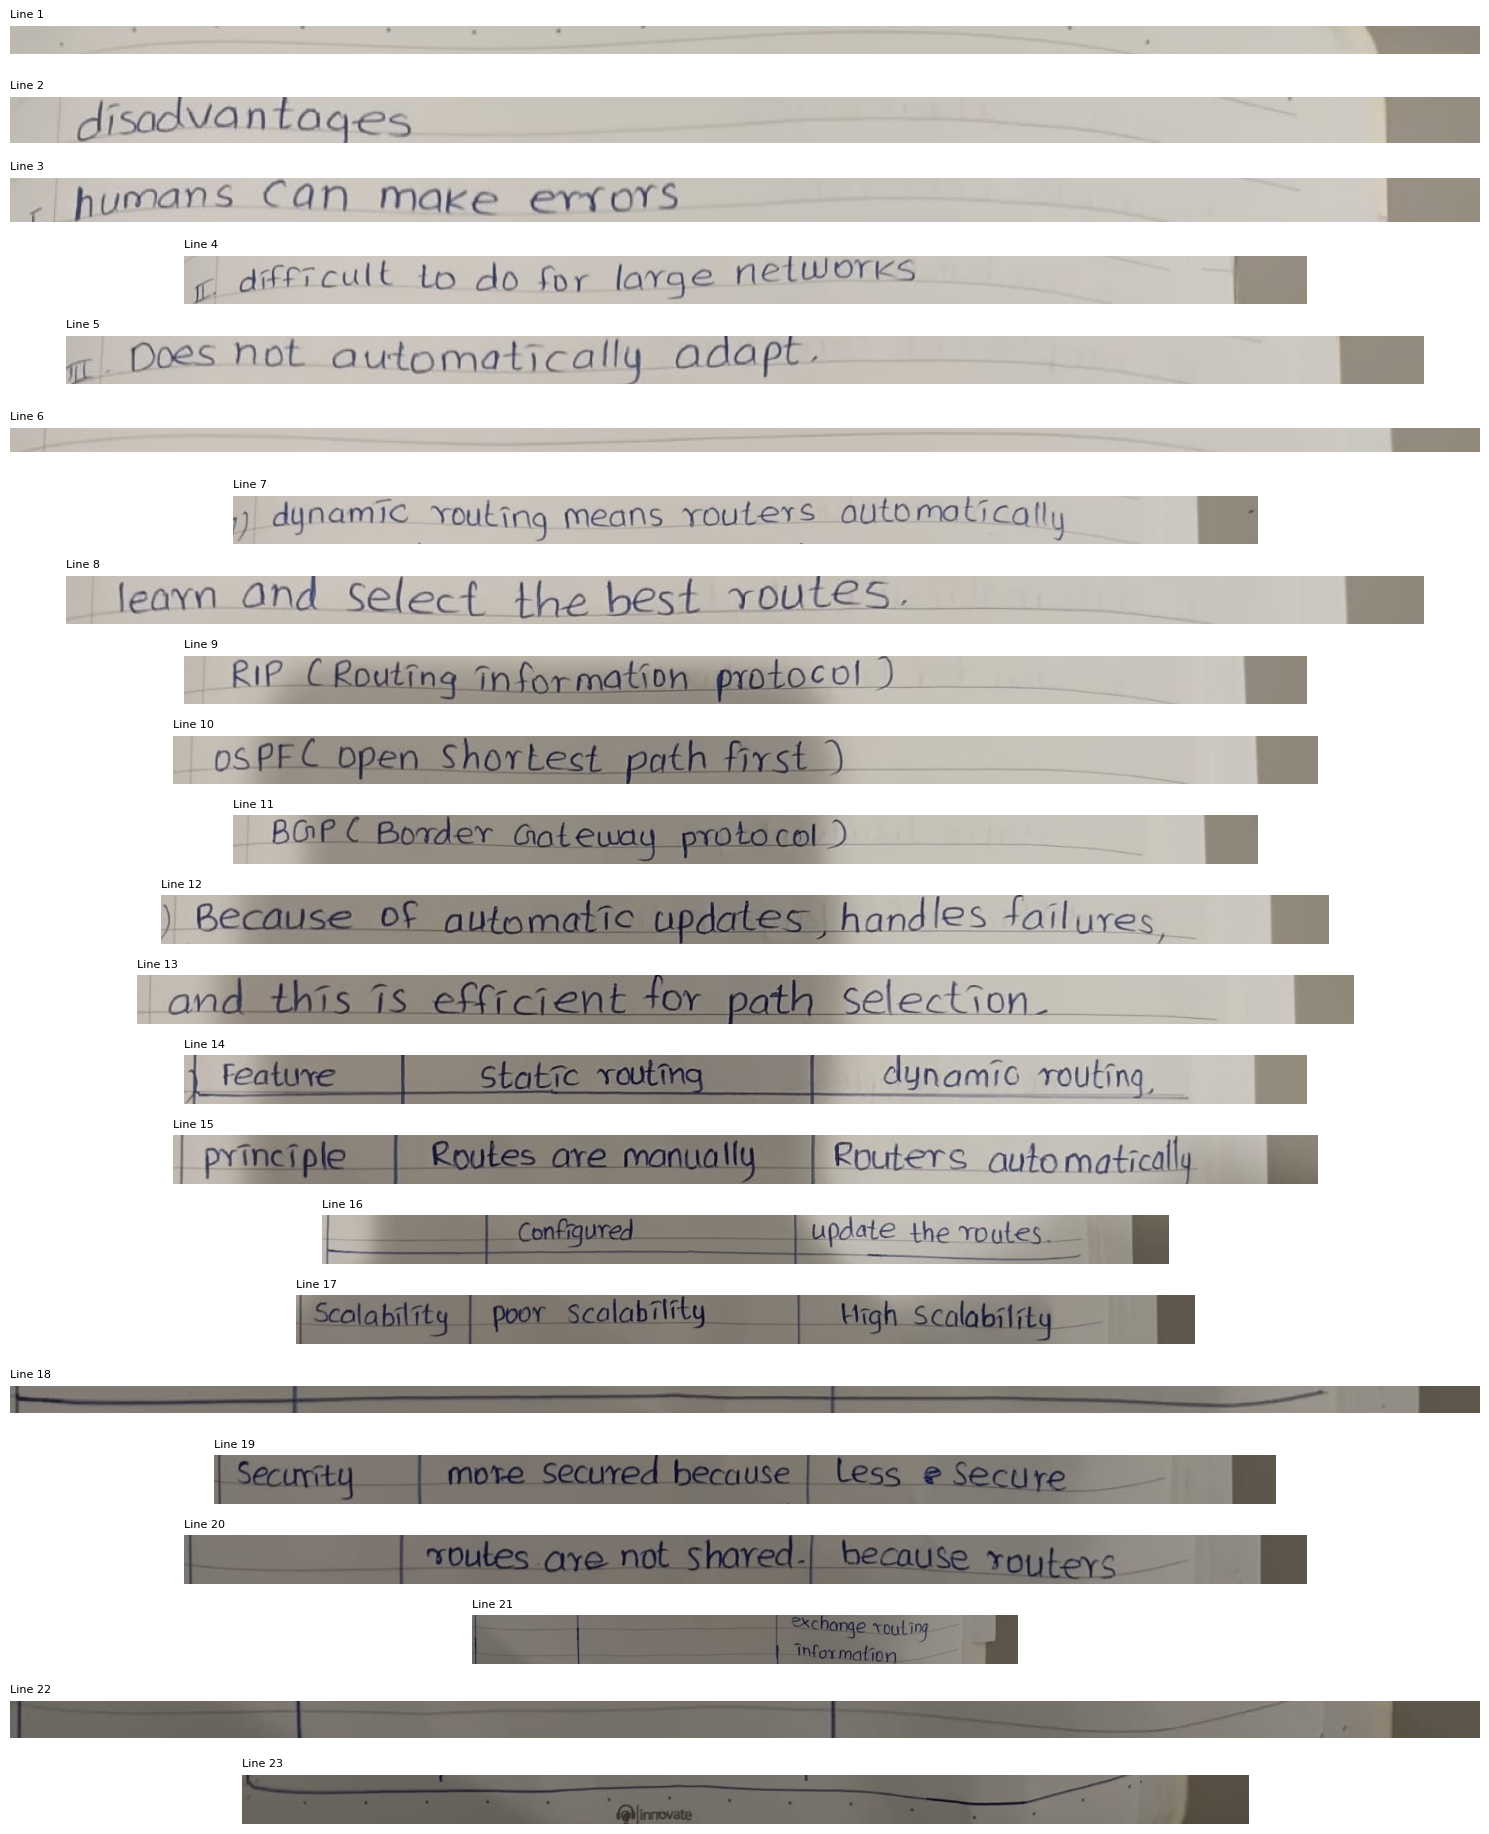

In [13]:
# Convert original grayscale image back for cropping (not the binary one, so we see actual handwriting)
img_color = Image.open("/content/WhatsApp Image 2026-08-10 at 12.14.22.jpeg").convert("RGB")
img_array = np.array(img_color)

fig, axes = plt.subplots(len(line_boundaries), 1, figsize=(15, len(line_boundaries)*0.8))

for idx, (start, end) in enumerate(line_boundaries):
    # small padding so we don't cut off ascenders/descenders (like tails of 'g', 'y')
    pad = 5
    crop = img_array[max(0, start-pad):min(img_array.shape[0], end+pad), :]
    axes[idx].imshow(crop)
    axes[idx].axis('off')
    axes[idx].set_title(f"Line {idx+1}", fontsize=8, loc='left')

plt.tight_layout()
plt.show()

In [14]:
# Filter out lines that are mostly blank (just a thin ruling line, not real text)
def has_real_text(start, end, threshold_ratio=0.15):
    segment = row_sums[start:end]
    return np.max(segment) > (noise_threshold * 3)  # real text has denser peaks than a thin rule line

line_boundaries = [b for b in line_boundaries if has_real_text(b[0], b[1])]
print(f"After filtering: {len(line_boundaries)} lines")

After filtering: 23 lines


In [15]:
extracted_lines = []

for idx, (start, end) in enumerate(line_boundaries):
    pad = 5
    crop = img_array[max(0, start-pad):min(img_array.shape[0], end+pad), :]
    line_image = Image.fromarray(crop).convert("RGB")

    # Run OCR on this single line
    pixel_values = processor(images=line_image, return_tensors="pt").pixel_values.to(device)
    generated_ids = model.generate(pixel_values, max_new_tokens=64)
    text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

    extracted_lines.append(text)
    print(f"Line {idx+1}: {text}")

Line 1: 1961 62.
Line 2: disadvantages
Line 3: humans can make errors
Line 4: difficult to do for large networks
Line 5: does not automatically adapt.
Line 6: 0
Line 7: sylvania routing means routers automatically
Line 8: learn and select the best routes.
Line 9: RIP ( Routing information protocol )
Line 10: OSPFL Open Shortest path first )
Line 11: BOP ( Border Gateway protocol )
Line 12: Because of automatic updates, handles failures,
Line 13: and this is efficient for path selection.
Line 14: Feature static routing dynamic routing,
Line 15: principle. Routes are manually. Reuters automatically
Line 16: configured update the routes.
Line 17: sedability poor sedability High scalability
Line 18: s.
Line 19: Security more secured because less secure.
Line 20: routes are not shared because runners.
Line 21: # exchange routing
Line 22: 0 0
Line 23: 1961 62


In [16]:
import re

def is_junk(text):
    text = text.strip()
    if len(text) < 3:
        return True
    if re.fullmatch(r'[\d\s.]+', text):  # only numbers/dots/spaces
        return True
    return False

final_lines = [line for line in extracted_lines if not is_junk(line)]
final_text = "\n".join(final_lines)

print("=== FINAL EXTRACTED NOTES ===")
print(final_text)

=== FINAL EXTRACTED NOTES ===
disadvantages
humans can make errors
difficult to do for large networks
does not automatically adapt.
sylvania routing means routers automatically
learn and select the best routes.
RIP ( Routing information protocol )
OSPFL Open Shortest path first )
BOP ( Border Gateway protocol )
Because of automatic updates, handles failures,
and this is efficient for path selection.
Feature static routing dynamic routing,
principle. Routes are manually. Reuters automatically
configured update the routes.
sedability poor sedability High scalability
Security more secured because less secure.
routes are not shared because runners.
# exchange routing


In [17]:
def ocr_handwritten_page(image_path, noise_threshold=5000, min_line_height=10, min_gap=8):
    # Step 1: Load and threshold
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    binary = cv2.adaptiveThreshold(
        img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV, blockSize=25, C=15
    )

    # Step 2: Detect line boundaries
    row_sums = np.sum(binary, axis=1)
    has_text = row_sums > noise_threshold

    raw_boundaries = []
    in_line, start = False, 0
    for i, val in enumerate(has_text):
        if val and not in_line:
            start, in_line = i, True
        elif not val and in_line:
            raw_boundaries.append((start, i))
            in_line = False
    if in_line:
        raw_boundaries.append((start, len(has_text)))

    merged = []
    for b in raw_boundaries:
        if merged and (b[0] - merged[-1][1]) < min_gap:
            merged[-1] = (merged[-1][0], b[1])
        else:
            merged.append(list(b))

    def has_real_text(s, e):
        return np.max(row_sums[s:e]) > (noise_threshold * 3)

    line_boundaries = [tuple(b) for b in merged
                        if (b[1]-b[0]) >= min_line_height and has_real_text(b[0], b[1])]

    # Step 3: Run OCR on each line
    img_color = Image.open(image_path).convert("RGB")
    img_array = np.array(img_color)

    extracted_lines = []
    for (start, end) in line_boundaries:
        pad = 5
        crop = img_array[max(0, start-pad):min(img_array.shape[0], end+pad), :]
        line_image = Image.fromarray(crop).convert("RGB")
        pixel_values = processor(images=line_image, return_tensors="pt").pixel_values.to(device)
        generated_ids = model.generate(pixel_values, max_new_tokens=64)
        text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
        extracted_lines.append(text)

    # Step 4: Filter junk and join
    def is_junk(text):
        text = text.strip()
        return len(text) < 3 or re.fullmatch(r'[\d\s.]+', text) is not None

    final_lines = [line for line in extracted_lines if not is_junk(line)]
    return "\n".join(final_lines)

In [18]:
result = ocr_handwritten_page("your_new_image.jpg")
print(result)

error: OpenCV(4.13.0) /io/opencv/modules/imgproc/src/smooth.dispatch.cpp:618: error: (-215:Assertion failed) !_src.empty() in function 'GaussianBlur'


In [19]:
result = ocr_handwritten_page("/content/WhatsApp Image 2026-08-10 at 12.14.22.jpeg")  # replace with your actual uploaded filename
print(result)

disadvantages
humans can make errors
difficult to do for large networks
does not automatically adapt.
sylvania routing means routers automatically
learn and select the best routes.
RIP ( Routing information protocol )
OSPFL Open Shortest path first )
BOP ( Border Gateway protocol )
Because of automatic updates, handles failures,
and this is efficient for path selection.
Feature static routing dynamic routing,
principle. Routes are manually. Reuters automatically
configured update the routes.
sedability poor sedability High scalability
Security more secured because less secure.
routes are not shared because runners.
# exchange routing


In [20]:
result = ocr_handwritten_page("/content/WhatsApp Image 2026-08-10 at 12.48.25.jpeg")  # use the real filename of the new upload
print(result)

1940s,
1919 HTTP is stainless because of every request to independent
the server does not remember the previous requests
will fillful to suggest out to only until several years were
Part-c. significantly
HD limitations of the Current monolithic Architecture.
# Lord to maintain " W.S.
U. Team Conflicts
IT DIFFicult to deployment.
1930s.


In [21]:
for idx, line in enumerate(extracted_lines):
    print(f"Line {idx+1}: {line}")

Line 1: 1961 62.
Line 2: disadvantages
Line 3: humans can make errors
Line 4: difficult to do for large networks
Line 5: does not automatically adapt.
Line 6: 0
Line 7: sylvania routing means routers automatically
Line 8: learn and select the best routes.
Line 9: RIP ( Routing information protocol )
Line 10: OSPFL Open Shortest path first )
Line 11: BOP ( Border Gateway protocol )
Line 12: Because of automatic updates, handles failures,
Line 13: and this is efficient for path selection.
Line 14: Feature static routing dynamic routing,
Line 15: principle. Routes are manually. Reuters automatically
Line 16: configured update the routes.
Line 17: sedability poor sedability High scalability
Line 18: s.
Line 19: Security more secured because less secure.
Line 20: routes are not shared because runners.
Line 21: # exchange routing
Line 22: 0 0
Line 23: 1961 62


In [22]:
def ocr_handwritten_page_debug(image_path, noise_threshold=5000, min_line_height=10, min_gap=8):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    binary = cv2.adaptiveThreshold(
        img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV, blockSize=25, C=15
    )
    row_sums = np.sum(binary, axis=1)
    has_text = row_sums > noise_threshold

    raw_boundaries = []
    in_line, start = False, 0
    for i, val in enumerate(has_text):
        if val and not in_line:
            start, in_line = i, True
        elif not val and in_line:
            raw_boundaries.append((start, i))
            in_line = False
    if in_line:
        raw_boundaries.append((start, len(has_text)))

    merged = []
    for b in raw_boundaries:
        if merged and (b[0] - merged[-1][1]) < min_gap:
            merged[-1] = (merged[-1][0], b[1])
        else:
            merged.append(list(b))

    def has_real_text(s, e):
        return np.max(row_sums[s:e]) > (noise_threshold * 3)

    line_boundaries = [tuple(b) for b in merged
                        if (b[1]-b[0]) >= min_line_height and has_real_text(b[0], b[1])]

    img_color = Image.open(image_path).convert("RGB")
    img_array = np.array(img_color)

    extracted = []
    for (s, e) in line_boundaries:
        pad = 5
        crop = img_array[max(0, s-pad):min(img_array.shape[0], e+pad), :]
        line_image = Image.fromarray(crop).convert("RGB")
        pixel_values = processor(images=line_image, return_tensors="pt").pixel_values.to(device)
        generated_ids = model.generate(pixel_values, max_new_tokens=64)
        text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
        extracted.append(text)

    return extracted, line_boundaries  # returns BOTH the text lines AND their pixel positions

# Run on your new image and inspect line-by-line
lines, boundaries = ocr_handwritten_page_debug("/content/WhatsApp Image 2026-08-10 at 12.48.25.jpeg")
for idx, line in enumerate(lines):
    print(f"Line {idx+1}: {line}")

Line 1: 1940s,
Line 2: 1919 HTTP is stainless because of every request to independent
Line 3: the server does not remember the previous requests
Line 4: will fillful to suggest out to only until several years were
Line 5: Part-c. significantly
Line 6: in
Line 7: HD limitations of the Current monolithic Architecture.
Line 8: # Lord to maintain " W.S.
Line 9: U. Team Conflicts
Line 10: IT DIFFicult to deployment.
Line 11: 1934
Line 12: 1903
Line 13: 1930s.
Line 14: 1903


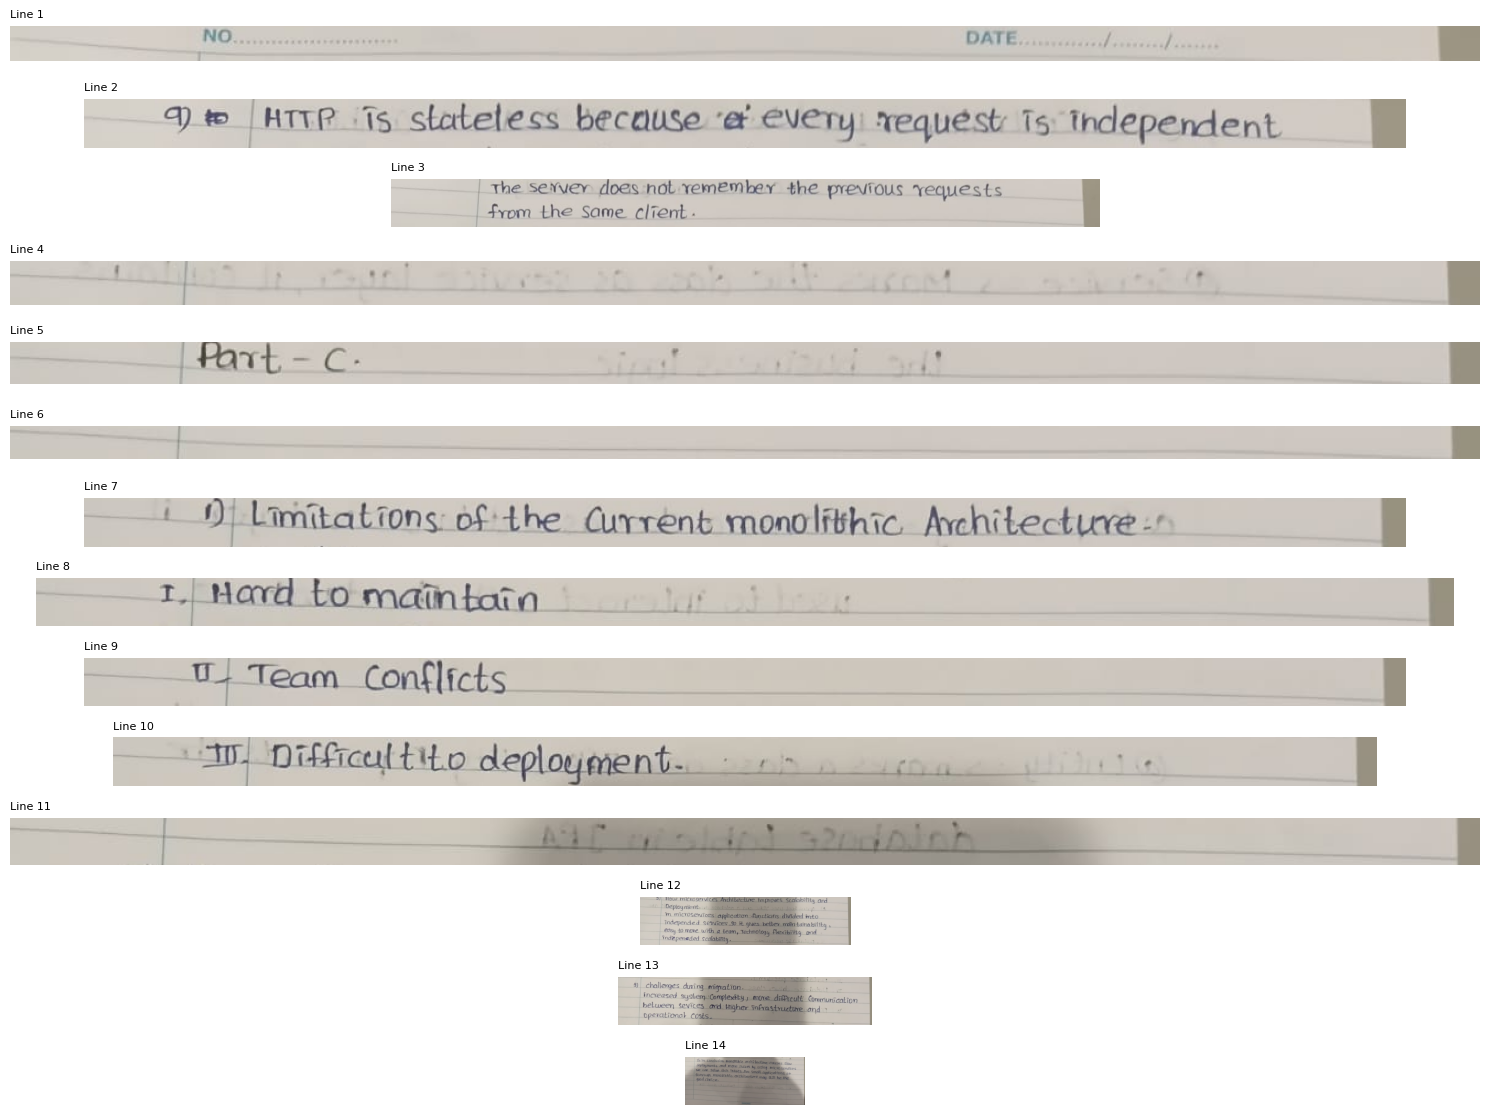

In [23]:
img_color = Image.open("/content/WhatsApp Image 2026-08-10 at 12.48.25.jpeg").convert("RGB")
img_array = np.array(img_color)

fig, axes = plt.subplots(len(boundaries), 1, figsize=(15, len(boundaries)*0.8))

for idx, (start, end) in enumerate(boundaries):
    pad = 5
    crop = img_array[max(0, start-pad):min(img_array.shape[0], end+pad), :]
    axes[idx].imshow(crop)
    axes[idx].axis('off')
    axes[idx].set_title(f"Line {idx+1}", fontsize=8, loc='left')

plt.tight_layout()
plt.show()

In [4]:
import sentencepiece
print(sentencepiece.__version__)

0.2.2


In [1]:
!pip install -q transformers==4.44.2 sentencepiece

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 85.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 33.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 81.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
!pip install sentencepiece -q